# EDA: Combined Unintegrated Data

- **Purpose:** Inspect tumor and cell line cells together in the shared gene space before integration.
- **Inputs:** `data/processed/preprocessed_tumor.h5ad`, `data/processed/preprocessed_cell_line.h5ad`.
- **Outputs:** `figures/EDA/EDA_combined_umap.png`.
- **Result:** The unintegrated UMAP separates the two datasets, motivating batch correction.


Concatenation of tumor and cell line objects in the shared gene space without batch correction. PCA/UMAP built on 5,000 HVGs selected from the counts without a batch key.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent.parent
DATA = ROOT / "data" / "processed"
FIGS = ROOT / "figures" / "EDA"

sc.settings.verbosity = 1
plt.rcParams.update({"font.size": 11, "axes.titlesize": 12})

In [2]:
tumor = ad.read_h5ad(DATA / "preprocessed_tumor.h5ad")
cl = ad.read_h5ad(DATA / "preprocessed_cell_line.h5ad")
adata = ad.concat([tumor, cl])
del tumor, cl
adata.shape

(110293, 28617)

# Unintegrated representations

In [3]:
sc.pp.highly_variable_genes(adata, n_top_genes=5000, flavor="seurat_v3")
adata = adata[:, adata.var["highly_variable"]].copy()

sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

sc.tl.pca(adata)
sc.pp.neighbors(adata)
sc.tl.umap(adata)

/mnt/bigdisk/markus/miniconda3/envs/scvi/lib/python3.11/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list
/mnt/bigdisk/markus/miniconda3/envs/scvi/lib/python3.11/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


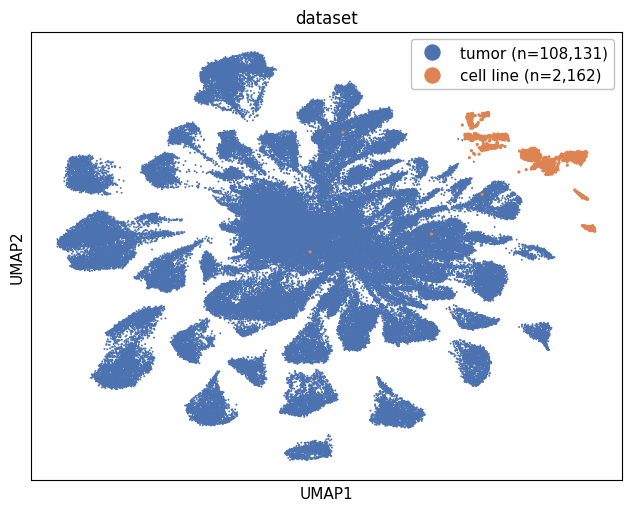

In [4]:
fig, ax = plt.subplots(1, 1, figsize=(6.2, 5), constrained_layout=True)
rng = np.random.default_rng(0)
d = adata[rng.permutation(adata.n_obs)].copy()

tumor = d[d.obs["dataset"] == "tumor"]
cl = d[d.obs["dataset"] == "cell_line"]

sc.pl.umap(tumor, color="dataset", ax=ax, show=False, size=8,
           palette={"tumor": "#4C72B0"}, legend_loc=None)
sc.pl.umap(cl, color="dataset", ax=ax, show=False, size=22,
           palette={"cell_line": "#DD8452"}, legend_loc=None)

# manual legend (since we split the plot into two calls)
from matplotlib.lines import Line2D
ax.legend(handles=[
    Line2D([], [], marker="o", ls="", color="#4C72B0", label=f"tumor (n={len(tumor):,})"),
    Line2D([], [], marker="o", ls="", color="#DD8452", label=f"cell line (n={len(cl):,})"),
], loc="upper right", frameon=True, markerscale=1.8).get_frame().set_edgecolor("0.7")

plt.savefig(FIGS / "EDA_combined_umap.png", dpi=200, bbox_inches="tight")

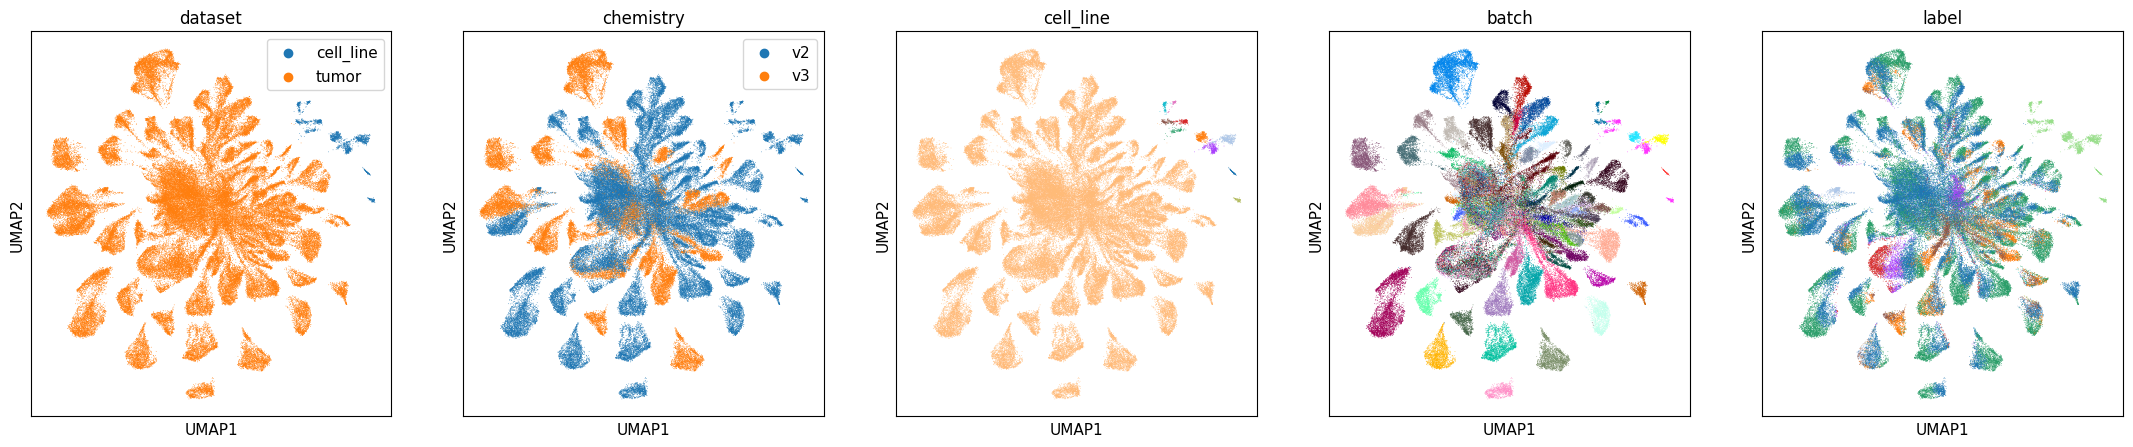

In [5]:
fig, axes = plt.subplots(1, 5, figsize=(27, 5))
rng = np.random.default_rng(0)
adata = adata[rng.permutation(adata.n_obs)].copy()
sc.pl.umap(adata, color="dataset", ax=axes[0], show=False, legend_loc="upper right")
sc.pl.umap(adata, color="chemistry", ax=axes[1], show=False, legend_loc="upper right")
sc.pl.umap(adata, color="cell_line", ax=axes[2], show=False, legend_loc=None)
sc.pl.umap(adata, color="batch", ax=axes[3], show=False, legend_loc=None)
sc.pl.umap(adata, color="label", ax=axes[4], show=False, legend_loc=None)
for i in (0, 1):
    axes[i].get_legend().set_frame_on(True)
#plt.savefig(FIGS / "EDA_combined_umap.png", dpi=200, bbox_inches="tight")